# Proyecto · Clase 2 — Una neurona que aprende de sus errores

En la Clase 1 las plantillas nunca cambiaban. Hoy construimos una **neurona artificial** (el *perceptrón* de
Rosenblatt, 1958) que **corrige sus números cada vez que se equivoca**.

Empezamos con una pregunta fácil: **¿esta imagen es un 0 o un 1?**

In [1]:
import os, urllib.request
if not os.path.exists("digitos.py"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/datahuba/curso-redes-neuronales/main/proyecto/digitos.py", "digitos.py")

import numpy as np
import matplotlib.pyplot as plt
from digitos import cargar_mnist, mostrar, ok

## 1. ¿Qué hace una neurona?
Recibe varias entradas, multiplica cada una por un **peso** (cuánto le importa), suma todo, le agrega un **sesgo**
`b` y decide:

$$\text{salida} = \begin{cases} 1 & \text{si } x_1 w_1 + x_2 w_2 + \dots + b > 0 \\ 0 & \text{si no} \end{cases}$$

Con NumPy, toda esa suma es una sola operación: `x @ w + b`.

✏️ **Calentamiento.** Una neurona de 2 entradas que funcione como la compuerta **Y (AND)**: solo responde 1 si
**las dos** entradas son 1. Busca a mano `w` y `b`. (Pista: prueba con pesos 1 y piensa qué sesgo hace falta.)

In [2]:
entradas = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
w_and = np.array([1.0, 1.0])
b_and = -1.5
print("x1 x2 → salida")
for x in entradas:
    print(x, "→", int(x @ w_and + b_and > 0))


x1 x2 → salida
[0 0] → 0
[0 1] → 0
[1 0] → 0
[1 1] → 1


In [3]:
ok([int(x @ w_and + b_and > 0) for x in entradas] == [0, 0, 0, 1], "tu neurona es una compuerta AND")

✅ tu neurona es una compuerta AND


Encontrar los pesos a mano funciona con 2 entradas. Pero una imagen tiene **784** entradas… nadie va a probar
pesos a mano. La neurona tiene que **aprenderlos**.

## 2. Los datos: solo ceros y unos

12665 imágenes para aprender, 2115 para el examen


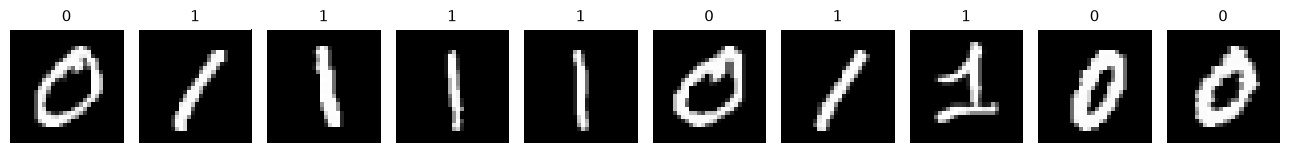

In [4]:
X_train, y_train, X_test, y_test = cargar_mnist()
X_train = X_train.reshape(-1, 784) / 255
X_test = X_test.reshape(-1, 784) / 255

A, B = 0, 1                      # 🔁 Desafío del final: cambia a 3 y 5
filtro = (y_train == A) | (y_train == B)
X, y = X_train[filtro], (y_train[filtro] == B).astype(int)        # y = 1 si es B, 0 si es A
filtro_t = (y_test == A) | (y_test == B)
Xt, yt = X_test[filtro_t], (y_test[filtro_t] == B).astype(int)
print(len(X), "imágenes para aprender,", len(Xt), "para el examen")
mostrar(X[:10], titulos=y[:10])

✏️ **Ejercicio 1.** Escribe la neurona: devuelve 1 si `x @ w + b > 0` y 0 si no.
Truco: `(condición).astype(int)` convierte `True/False` en `1/0`, y funciona igual con **muchas** imágenes a la vez.

In [5]:
def neurona(x, w, b):
    return (x @ w + b > 0).astype(int)

rng = np.random.default_rng(0)
w = rng.normal(0, 0.01, 784)     # pesos al azar: la neurona todavía no sabe nada
b = 0.0
print(f"Precisión con pesos al azar: {(neurona(Xt, w, b) == yt).mean():.1%}")


Precisión con pesos al azar: 56.3%


In [6]:
ok(neurona(np.ones((2, 784)), np.ones(784), -800).tolist() == [0, 0], "la neurona devuelve 0/1 para cada fila")

✅ la neurona devuelve 0/1 para cada fila


## 3. La regla de aprendizaje (Rosenblatt)
Mostramos las imágenes de una en una. Después de cada respuesta:

- **Acertó** → no se toca nada.
- Dijo 0 y era 1 → error = **+1** → sube los pesos de los píxeles encendidos («esos píxeles eran señal de 1»).
- Dijo 1 y era 0 → error = **−1** → bájalos.

$$\text{error} = y - \hat y \qquad w \leftarrow w + \eta \cdot \text{error} \cdot x \qquad b \leftarrow b + \eta \cdot \text{error}$$

`η` (*eta*) es la **tasa de aprendizaje**: el tamaño de cada corrección.

✏️ **Ejercicio 2.** Completa las dos líneas de la corrección.

In [7]:
def entrenar(X, y, eta=0.1, epocas=3):
    w, b = np.zeros(X.shape[1]), 0.0
    for epoca in range(epocas):              # una época = ver todas las imágenes una vez
        errores = 0
        for xi, yi in zip(X, y):
            error = yi - neurona(xi, w, b)
            w = w + eta * error * xi
            b = b + eta * error
            errores += abs(error)
        print(f"época {epoca + 1}: se equivocó {errores} veces")
    return w, b

w, b = entrenar(X, y)
precision = (neurona(Xt, w, b) == yt).mean()
print(f"Precisión en el examen: {precision:.2%}")


época 1: se equivocó 45 veces


época 2: se equivocó 24 veces


época 3: se equivocó 26 veces
Precisión en el examen: 99.81%


In [8]:
ok(precision > 0.98, "la neurona distingue el 0 del 1 casi siempre")

✅ la neurona distingue el 0 del 1 casi siempre


## 4. ¿Qué aprendió? Miremos los pesos
Los 784 pesos se pueden volver a dibujar como una imagen de 28 × 28.
**Rojo** = «este píxel encendido me hace decir 1» · **azul** = «me hace decir 0».

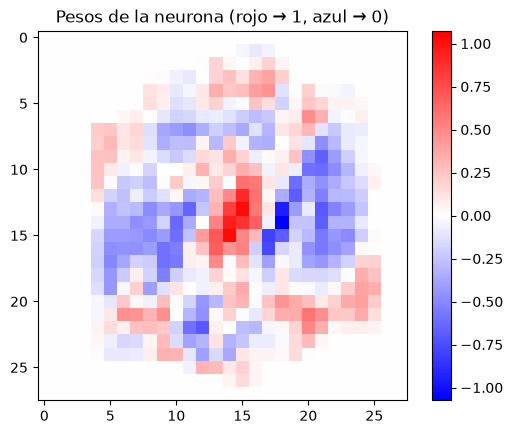

In [9]:
plt.imshow(w.reshape(28, 28), cmap="bwr", vmin=-abs(w).max(), vmax=abs(w).max())
plt.title(f"Pesos de la neurona (rojo → {B}, azul → {A})")
plt.colorbar()
plt.show()

## 5. Desafío 🔁
1. Arriba cambia `A, B = 0, 1` por `A, B = 3, 5` y vuelve a ejecutar todo. ¿Qué pasa con los errores por época
   y con la precisión? ¿Por qué es más difícil?
2. Prueba `epocas=10`. ¿Llega a cero errores?

## Lo que nos llevamos
- Una neurona = **suma ponderada + decisión**. Los pesos dicen qué le importa.
- Aprender = **corregir los pesos cuando se equivoca**.
- Problema: la regla solo sabe si acertó o no, **no cuánto** se equivocó. Y con 3 vs 5 nunca deja de saltar.

**Clase 3:** una neurona que dice *«es un 5 con 80 % de seguridad»* y aprende bajando poco a poco su error
(descenso por gradiente).